# Transcript Intelligence: analysis notebook

**What this is:** the reference implementation behind the slide deck. Every number in the deck is produced here.
The heavy lifting lives in the `ti/` package (`load` → `classify` → `sentiment` → `insights` → `charts`); this
notebook calls it step by step and explains the decisions.

| Section | Question |
|---|---|
| 1 | What's in the data, and what did I change? |
| 2 | **Task 1:** how are calls categorised, and why this approach? |
| 3 | **Task 2:** what does sentiment look like across call types, and what does it mean? |
| 4 | **Task 3:** what else can stakeholders get from this data? |
| 5 | Limitations and what I'd do next |

Run everything end-to-end from the CLI with `python run_pipeline.py` (≈4s).

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 200)

from ti.load import load
from ti.classify import classify, discover_topics, evaluate
from ti import sentiment as S, insights as I, charts
from pathlib import Path
OUT = Path('../outputs/charts')

t = load()
m, s, km = t['meetings'], t['sentences'], t['key_moments']
print(f"{len(m)} meetings | {len(s):,} sentences | {m.n_words.sum():,} words | {m.start.min():%b %d} – {m.start.max():%b %d %Y}")

100 meetings | 4,313 sentences | 141,357 words | Feb 03 – Apr 28 2026


## 1. The data, and what I changed

Each of the 100 folders is one recorded meeting: `meeting-info.json`, a sentence-level `transcript.json` (with a
vendor sentiment label per sentence), a vendor `summary.json` (summary, free-text topics, typed *key moments*,
action items, a 1–5 sentiment score), plus speaker turns and join/leave events.

**Call types aren't labelled.** I derived them from metadata rather than text, because *who is on the call*
is a structural fact:

* no external email domain → **internal**
* external participants **and** a support-style title (`Support Case #`, `URGENT:`, `ESCALATION:`) or a summary saying
  the customer contacted support → **support**
* otherwise → **external** (account management: renewals, QBRs, onboarding, feedback)

**Speaker side.** I mapped every speaker name to an email (311/311 matched) so every sentence is tagged
*customer* or *Aegis employee*. This turns out to be the single most useful enrichment (section 3).

**No synthetic data was added.** The three call types come out balanced (40/30/30), so there was no gap to fill.
I'd rather show real signal than pad it.

In [2]:
m = classify(t)
display(m.call_type.value_counts().to_frame('calls'))
m.groupby('call_type').apply(lambda g: g.sample(3, random_state=1)[['title','call_type_reason']]).droplevel(0)

,calls
call_type,
external,40
support,30
internal,30


,title,call_type_reason
7,Aegis / Brightpath Commerce - Detect Module Deployment,"external participants, account-management style title"
81,Aegis / Axiom Labs - Multi-Year Renewal,"external participants, account-management style title"
9,Aegis / Bridgeport Health - Compliance Review,"external participants, account-management style title"
60,Identity Team - Sprint Retro,no external participants
72,Competitive Response Strategy,no external participants
36,Detect Outage - Escalation Bridge,no external participants
49,Support Case #7537 - Forge Industries Detect Recovery Confirmation,title matches support/urgent/escalation pattern
65,Support Case #1993 - Forge Industries Comply v2 Early Access Question,title matches support/urgent/escalation pattern
34,URGENT: Cobalt Software - Aegis Detect Dashboard Down,title matches support/urgent/escalation pattern


## 2. Task 1: categorising calls by topic

### Step 1: Look at what's already there
The vendor summaries ship with free-text topics. They are **too fragmented to use directly**: 351 unique strings for
100 calls ("outage", "platform outage", "service outage", "outage post-mortem", ...).

In [3]:
topics = pd.Series([x for ts in m.topics for x in ts])
print(topics.nunique(), 'unique topic strings; top 15:')
topics.value_counts().head(15)

351 unique topic strings; top 15:


compliance                 23
compliance reporting       19
renewal                    17
churn risk                 14
onboarding                  9
incident response           8
outage                      8
incident communication      7
product launch              7
platform outage             6
feature request             6
multi-framework support     5
service outage              5
identity management         5
product roadmap             5
Name: count, dtype: int64

### Step 2: Unsupervised discovery (what does the data say?)
TF-IDF + NMF over the raw transcripts, with no labels involved. This shows which natural groupings exist before I impose any.

In [4]:
m['cluster'], clusters = discover_topics(m)
clusters

,cluster,top_terms
0,0,"renewal, proposal, outage, failure, pricing, maria, contract, technical"
1,1,"monitoring, failure, event processing, incident, processing, pipeline, threat, engineering"
2,2,"identity, mfa, sso, okta, saml, session, policy, role"
3,3,"sprint, nina, qa, ravi, tyler, test, node, testing"
4,4,"evidence, control, framework, soc, v2, controls, audit, pci"
5,5,"billing, invoice, overage, charge, usage, tier, limit, january"
6,6,"cloudprime, prem, backup, onboarding, restore, phase, recovery, retention"
7,7,"competitive, vaultedge, tom, sentinelshield, cybernova, deals, prospect, conversations"
8,8,"seeing, error, issue, jobs, fix, endpoint, connection, connector"


The clusters are coherent: billing, identity/SSO, competitive, connector errors, audit evidence, onboarding/backup,
incident pipeline, sprint work. They also show **why clustering alone isn't the answer**: they mix *product*
(cluster "identity, mfa, sso") with *business intent* (cluster "billing, invoice, overage"). A support leader routing
calls needs intent; a PM needs product. So I split those into separate dimensions.

### Step 3: A curated taxonomy, with three independent dimensions
| Dimension | Method | Why |
|---|---|---|
| **Call type** | metadata rules | structural, ~100% reliable |
| **Product** (Detect / Protect / Comply / Identity / LogVault) | lexicon counts | products are proper nouns |
| **Theme** (10 business themes, multi-label + one primary) | weighted keyword scoring over title, summary, vendor topics, key-moment types and transcript, × call-type prior | explainable, deterministic, free; every label carries its evidence |

The 10 themes were chosen from the discovery clusters plus the decisions stakeholders make
(e.g. *Billing* is separate from *Product defect* because they route to different teams).

**Why not LLM-only?** On 100 calls, rules are cheaper, faster and auditable, and they hit 87% (below). I built the
LLM path (`ti/llm_classify.py`, Claude with a JSON schema) as the **scale-out plan**: keyword lists rot as products
change, and in production you'd run both and send disagreements to a human.

In [5]:
from ti.taxonomy import THEMES
pd.DataFrame([(k, v['label'], v['desc']) for k, v in THEMES.items()], columns=['key','theme','definition'])

,key,theme,definition
0,OUTAGE_INCIDENT,Outage & Incident Response,"Live or recent service outage: war rooms, escalations, RCAs, post-incident reviews."
1,PRODUCT_DEFECT,Product Defect & Performance,"Bug, regression, failing connector or degraded performance (outside the major outage)."
2,BILLING,Billing & Invoicing,"Invoice disputes, overage charges, proration, seat counts."
3,RENEWAL_EXPANSION,Renewal & Expansion,"Renewals, QBRs, account reviews, upsell / cross-sell on a healthy account."
4,CHURN_COMPETITIVE,Churn Risk & Competitive Pressure,"Customer evaluating alternatives, eroded trust, or internal competitive / win-loss strategy."
5,COMPLIANCE_AUDIT,Compliance & Audit Readiness,SOC 2 / HIPAA / PCI DSS / ISO 27001 preparation and evidence collection.
6,FEATURE_GAP,Feature Request & Product Feedback,Customer asks for capability that does not exist yet; structured product feedback.
7,ONBOARDING,Onboarding & Adoption,"Kickoffs, deployments, implementation planning, tuning after go-live."
8,LAUNCH,Product Launch (Comply v2),"Comply v2 design, launch readiness, GA, early-access demos and adoption tracking."
9,PLANNING,Engineering Planning & Roadmap,"Internal sprint planning, retros, standups, roadmap and all-hands."


### Step 4: Validate
Before writing any rules I hand-labelled a primary theme for all 100 calls from their summaries
(`data/gold_labels.csv`). The classifier is scored against those labels.

In [6]:
acc, ev = evaluate(m, '../data/gold_labels.csv')
print(f"Primary theme matches hand label: {acc:.0%}")
print(f"Hand label appears in the multi-label set: {ev.in_multilabel.mean():.0%}")
print(f"Calls with >1 theme: {(m.themes.str.len()>1).mean():.0%}")
ev[~ev.primary_match][['title','gold','pred']]

Primary theme matches hand label: 87%
Hand label appears in the multi-label set: 99%
Calls with >1 theme: 36%


,title,gold,pred
0,Support Case #3286 - Vanta Health Systems API Integration Error,PRODUCT_DEFECT,OUTAGE_INCIDENT
8,Comply v2 - Design Review,LAUNCH,COMPLIANCE_AUDIT
11,Weekly Engineering Standup,PLANNING,LAUNCH
24,All Hands - February Wrap,PLANNING,LAUNCH
42,Aegis / Meridian Capital - Service Reliability Discussion,OUTAGE_INCIDENT,CHURN_COMPETITIVE
52,Competitive Threat Assessment - Post Outage,CHURN_COMPETITIVE,OUTAGE_INCIDENT
59,Aegis / Ironclad Financial - Account Recovery Check-in,CHURN_COMPETITIVE,OUTAGE_INCIDENT
64,Aegis / Silverline Brands - Comply v2 Early Access Demo,LAUNCH,COMPLIANCE_AUDIT
76,Identity Team - Q2 Roadmap,PLANNING,CHURN_COMPETITIVE
78,Support Case #6147 - Summit Trust Detect Alert Delays,PRODUCT_DEFECT,OUTAGE_INCIDENT


**Reading the misses:** nearly all are genuinely multi-topic meetings: standups and all-hands that discuss *both*
the outage and the Comply v2 launch, or an account call that is both "post-incident" and "churn risk". In every
case but one, the hand label is still in the multi-label set. That's why the output is multi-label: forcing one
bucket loses information.

### Step 5: Results: categories with examples

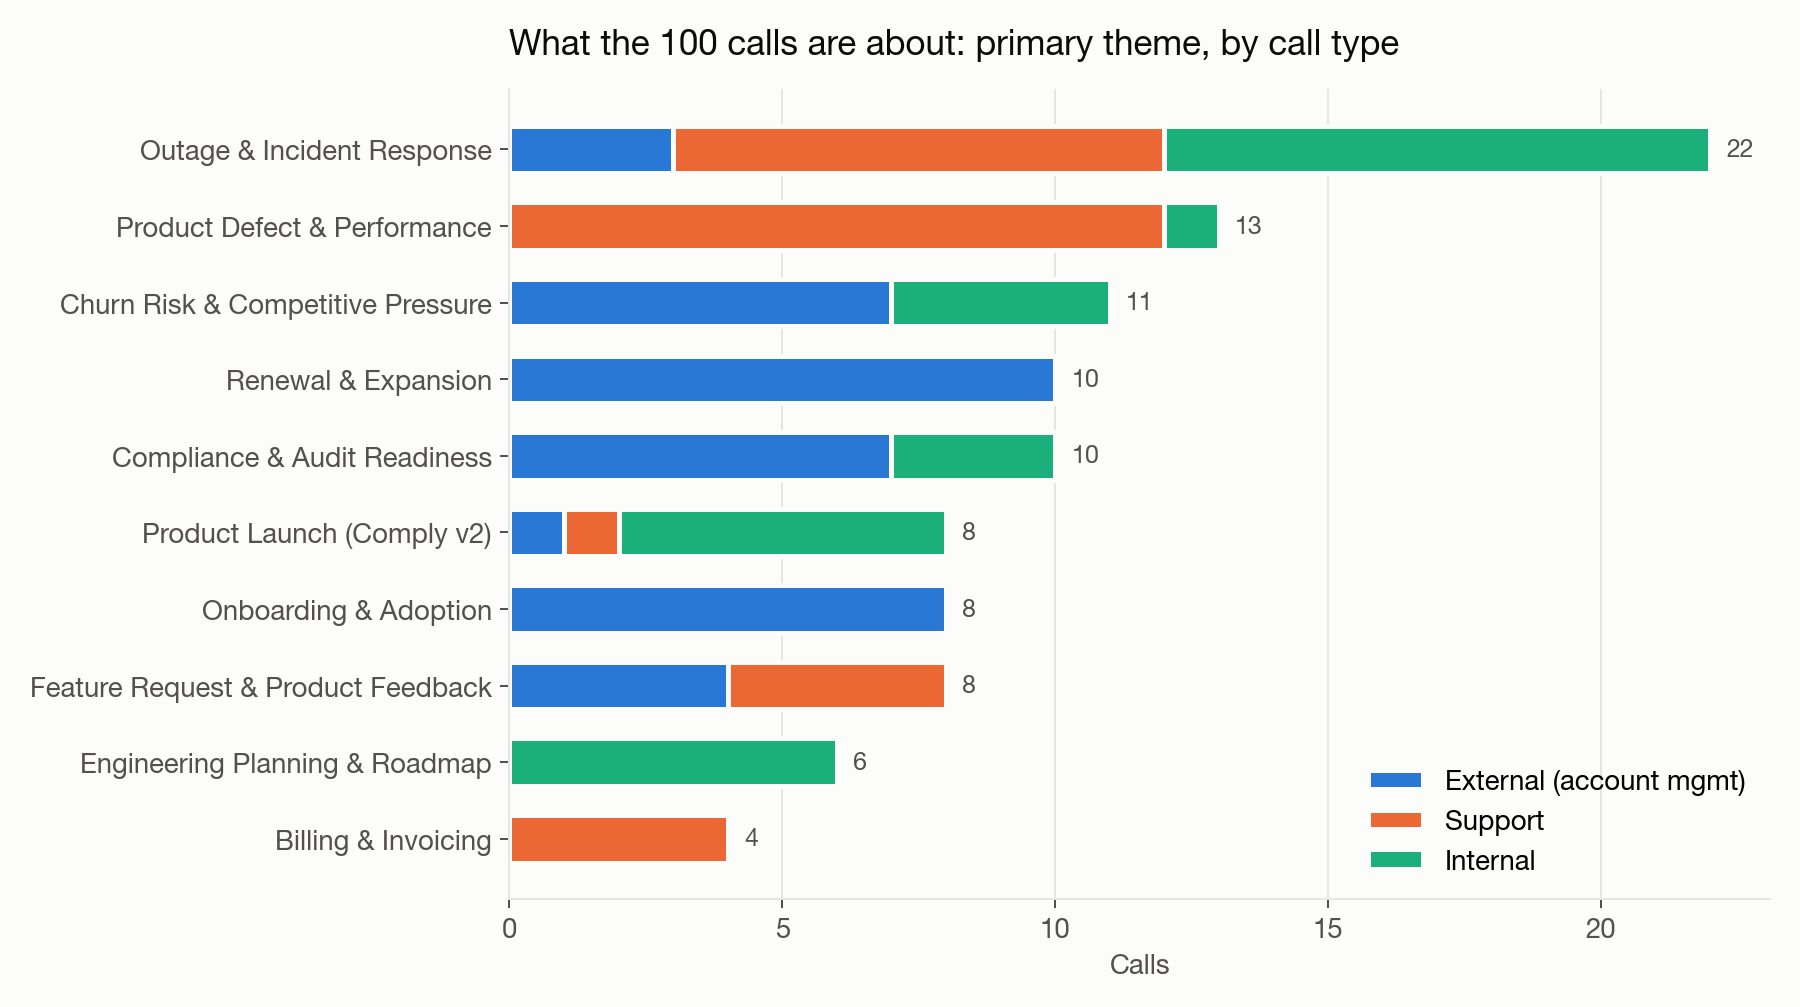

,calls,call_types,examples
theme_label,,,
Outage & Incident Response,22,"internal:10, support:9, external:3",Detect Outage - Post-Incident Review | Detect Outage - Remediation Plan Review | Detect Outage - Root Cause Analysis
Product Defect & Performance,13,"support:12, internal:1",Support Case #1750 - Vanta Health Systems SIEM Connector Issue | Support Case #6977 - Brightpath Commerce Slow Backu...
Churn Risk & Competitive Pressure,11,"external:7, internal:4",Competitive Landscape Review | Win/Loss Analysis - Q1 | Aegis / Ironworks Corp - Vendor Comparison Discussion
Compliance & Audit Readiness,10,"external:7, internal:3",Aegis / Stratos Cloud - Audit Preparation | Aegis / Blackridge Investments - HIPAA Compliance Review | Aegis / Maple...
Renewal & Expansion,10,external:10,Aegis / Crestline Wealth - Account Review | Aegis / Pineridge Systems - Q1 Business Review | Aegis / Atlas Precision...
Feature Request & Product Feedback,8,"support:4, external:4",Support Case #3546 - Meridian Capital SCIM Provisioning Request | Support Case #3615 - Nimbus Platform Custom Report...
Onboarding & Adoption,8,external:8,Aegis / Frostbyte AI - Identity Module Setup | Aegis / Harborview Banking - Threat Detection Tuning | Aegis / Vanta ...
Product Launch (Comply v2),8,"internal:6, support:1, external:1",Comply v2 - GA Deployment Plan | Comply v2 - Launch Day Checklist | Comply v2 - Adoption Metrics Review
Engineering Planning & Roadmap,6,internal:6,Protect Team - Quarterly Planning | Product Sync - Identity Roadmap | Detect Team - Sprint Planning


In [7]:
display(Image(OUT / '01_themes_by_call_type.png'))
ex = (m.sort_values('theme_margin', ascending=False).groupby('theme_label')
        .apply(lambda g: pd.Series({'calls': len(g), 'call_types': ', '.join(f"{k}:{v}" for k,v in g.call_type.value_counts().items()),
                                    'examples': ' | '.join(g.title.head(3))})))
ex.sort_values('calls', ascending=False)

In [8]:
# The evidence trail for one call: why did it land where it did?
r = m[m.title.str.contains('Quantum Edge')].iloc[0]
print(r.title); print('primary:', r.primary_theme, '| all:', r.themes, '| margin:', r.theme_margin)
print('evidence:', r.theme_evidence)
print({k: v for k, v in sorted(r.theme_scores.items(), key=lambda kv: -kv[1])[:4]})

Aegis / Quantum Edge - Renewal Concerns
primary: CHURN_COMPETITIVE | all: ['CHURN_COMPETITIVE', 'RENEWAL_EXPANSION'] | margin: 0.27
evidence: ['title:5', 'summary:sentinelshield|vaultedge|cybernova|fortiguard', 'summary:competit', 'summary:evaluat\\w+ (a |an )?(competitor|alternative)', 'topic:competit', 'topic:\\bsla\\b']
{'CHURN_COMPETITIVE': 32.26, 'RENEWAL_EXPANSION': 23.67, 'OUTAGE_INCIDENT': 13.12, 'COMPLIANCE_AUDIT': 6.34}


## 3. Task 2: sentiment across call types

### First, can we trust the sentiment labels?
The vendor gives a 1–5 meeting score and a pos/neu/neg label per sentence. Before building on them I re-scored every
sentence with an independent model (VADER) and compared.

In [9]:
s = S.score_sentences(s)
m = S.meeting_sentiment(m, s)
a = S.label_agreement(s)
print(f"Sentence-level exact agreement: {a['exact_agreement']:.0%} | direction agreement (ignoring neutrals): {a['direction_agreement']:.0%}")
display(a['crosstab'])
m[['vendor_sentiment_score','nsi_customer','nsi_internal','nsi_vader']].corr().round(2)

Sentence-level exact agreement: 46% | direction agreement (ignoring neutrals): 78%


vader_label,negative,neutral,positive
vendor_label,,,
negative,0.25,0.36,0.39
neutral,0.06,0.35,0.58
positive,0.02,0.16,0.82


,vendor_sentiment_score,nsi_customer,nsi_internal,nsi_vader
vendor_sentiment_score,1.00,0.96,0.84,0.83
nsi_customer,0.96,1.00,0.86,0.85
nsi_internal,0.84,0.86,1.00,0.81
nsi_vader,0.83,0.85,0.81,1.00


**What this tells us:**
* At the **meeting level** the signals agree (vendor score vs. independent VADER: r = 0.83). The trend lines are trustworthy.
* At the **sentence level**, a generic lexicon misses this domain: VADER catches only **25%** of the sentences the
  vendor marks negative. Phrases like *"we were blind for six hours"* and *"zero visibility"* aren't negative words to a
  general-purpose model. **Implication for the product:** don't ship off-the-shelf sentiment; use a domain-tuned or LLM scorer.
* The vendor meeting score correlates **0.96 with the customer-only sentiment** and 0.84 with the rep-only. The meeting
  score is essentially *the customer's mood*, which is what we want.

### Customer voice vs. rep voice

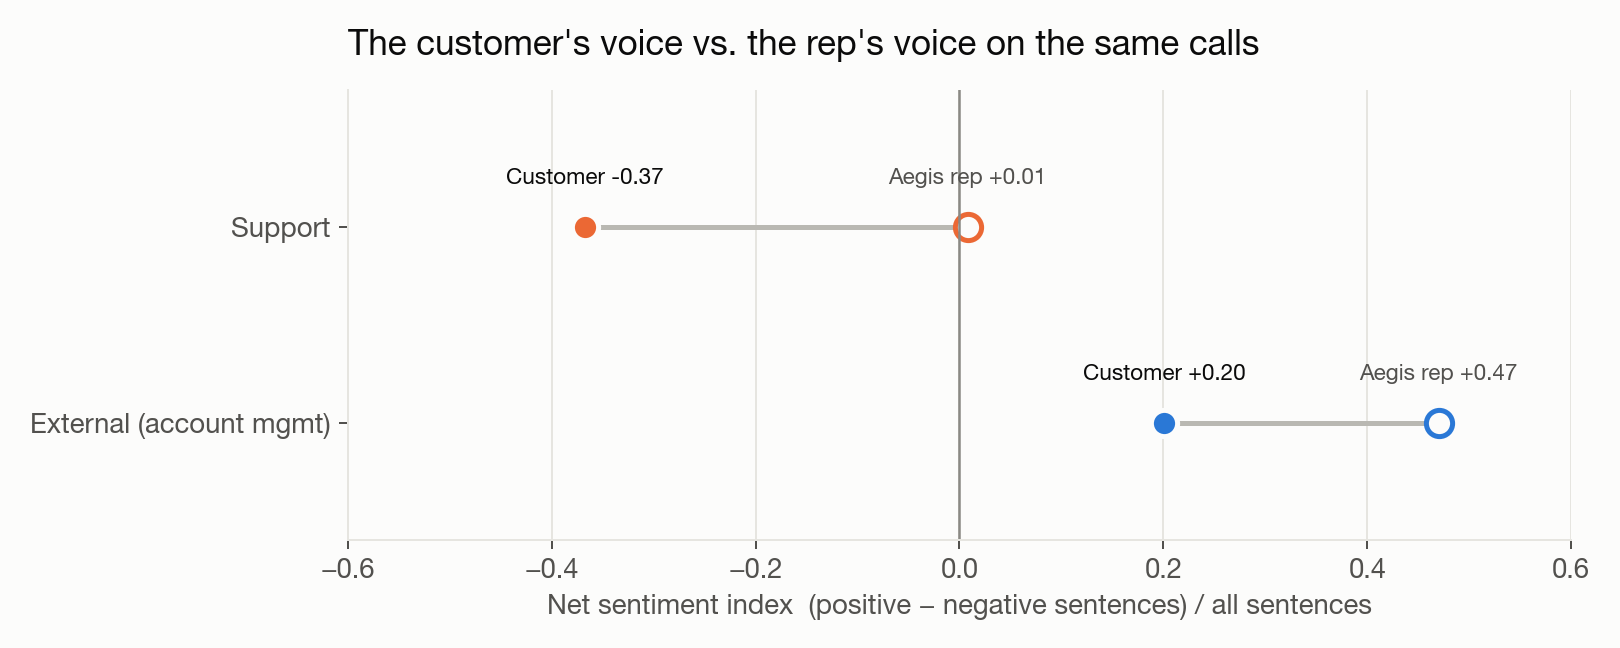

vendor_label,negative,neutral,positive
side,,,
customer,0.29,0.46,0.26
internal,0.11,0.62,0.28


In [10]:
display(Image(OUT / '04_customer_vs_rep.png'))
s.groupby('side').vendor_label.value_counts(normalize=True).unstack().round(2)

Customers say something negative in **29%** of their sentences; Aegis staff in **11%**. On support calls the gap is
0.38 NSI points. **Reps are professionally positive, so blended call sentiment understates customer pain.** Any
dashboard in this product should default to the *customer-side* score.

### By call type, over time

,calls,vendor_score,nsi_customer,nsi_internal,nsi_all,cust_arc_delta
call_type,,,,,,
external,40,3.85,0.20,0.47,0.34,0.36
internal,30,3.42,NaN,0.04,0.04,NaN
support,30,2.83,-0.37,0.01,-0.17,0.23


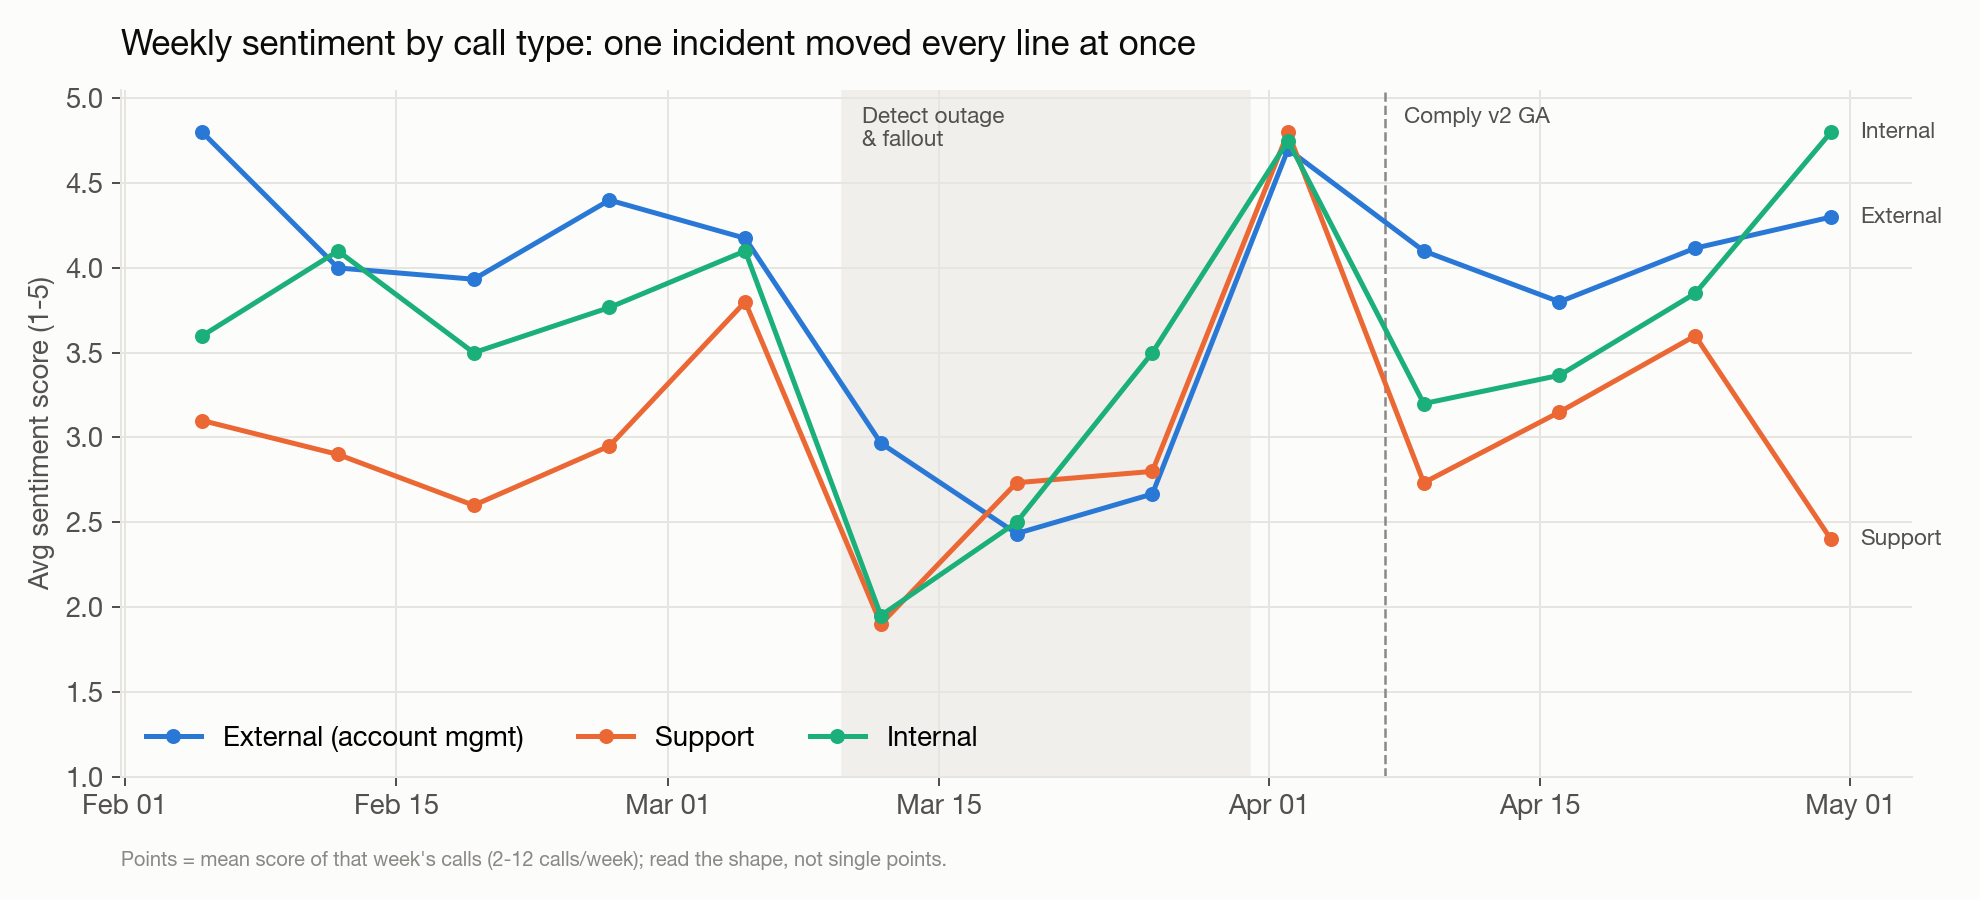

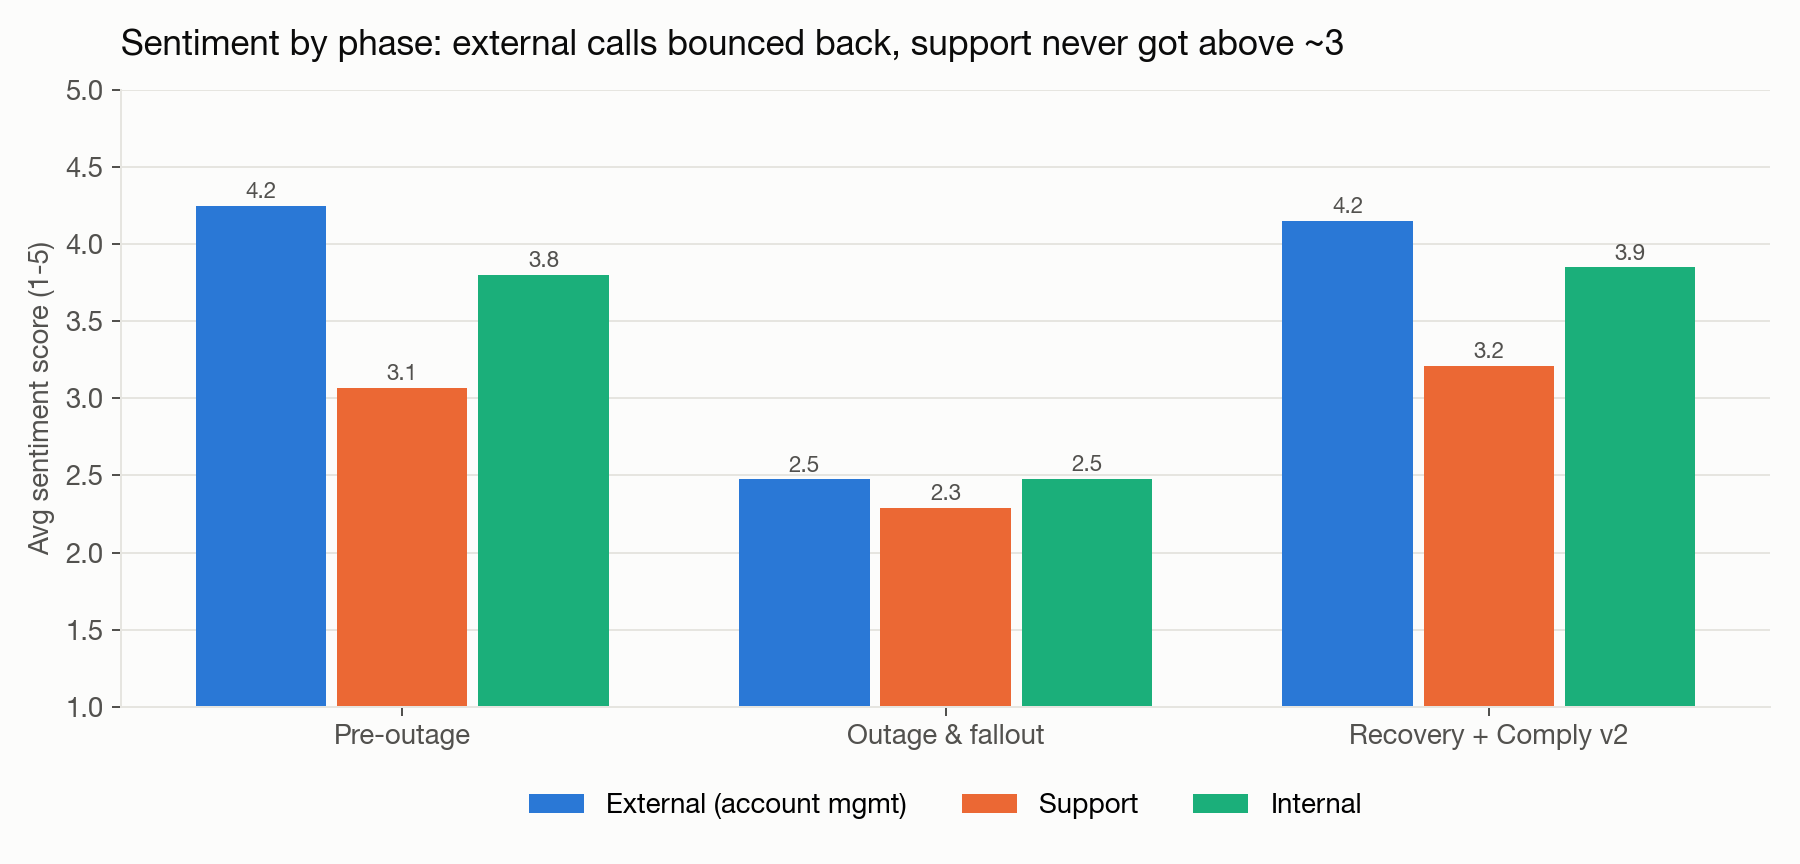

call_type,external,internal,support
phase,,,
1. Pre-outage,4.25,3.80,3.07
2. Outage & fallout,2.48,2.48,2.29
3. Recovery + Comply v2,4.15,3.85,3.21


call_type,external,internal,support
phase,,,
1. Pre-outage,15,9,10
2. Outage & fallout,8,9,11
3. Recovery + Comply v2,17,12,9


In [11]:
tabs = S.summary_tables(m)
display(tabs['by_type'])
display(Image(OUT / '02_weekly_sentiment.png'))
display(Image(OUT / '03_sentiment_by_phase.png'))
display(tabs['by_phase']); tabs['by_phase_n']

**What the trends mean:**

1. **Support is structurally the lowest (2.8)**, which is expected because people call support when something is broken. The
   useful signal is *change* in support sentiment, not its level.
2. **One incident moved every line at once.** In the outage window (Mar 10–31) external, internal *and* support
   sentiment all collapsed to ~2.3–2.5. Internal sentiment dropping as hard as customer sentiment matters:
   the outage cost the team morale and sprint capacity (two other teams' retros say so), not just customer trust.
3. **External sentiment "recovered" to 4.15 in April, and the average hides what's underneath.** April external calls are
   bimodal: Comply v2 demos and renewals at 4.7–4.8, competitive-evaluation calls at 2.6. The average says
   "we're fine"; the account view (section 4) says 9 accounts are at risk.
4. **Support did not recover the same way.** April support calls are back to pre-outage levels, but a new kind of
   ticket appears: problems *caused by the outage fix* (section 4).

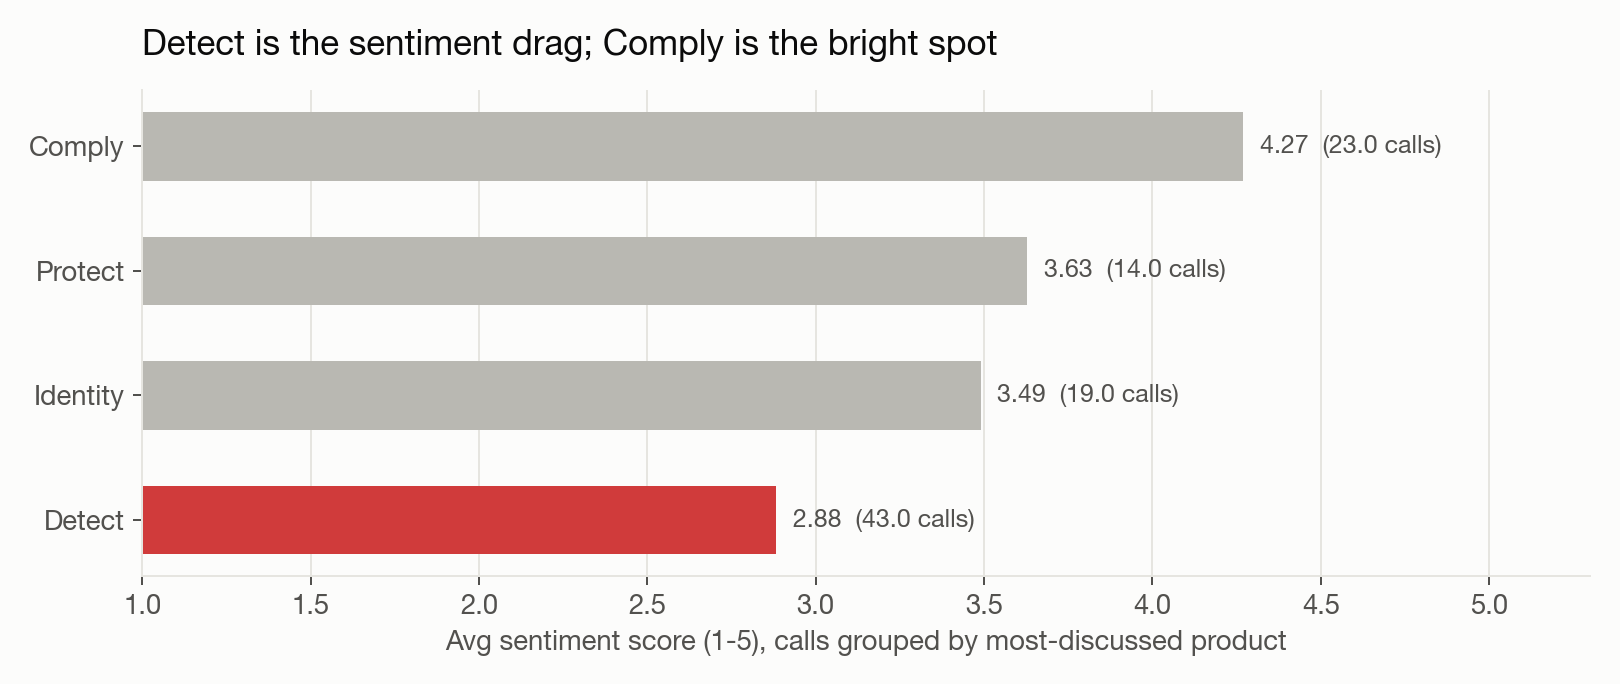

,calls,vendor_score,nsi_customer
primary_product,,,
LogVault,1,2.40,-0.57
Detect,43,2.88,-0.43
Identity,19,3.49,-0.01
Protect,14,3.63,0.12
Comply,23,4.27,0.40


,calls,vendor_score,nsi_customer,cust_arc_delta
theme_label,,,,
Outage & Incident Response,22,2.36,-0.67,0.32
Product Defect & Performance,13,2.57,-0.47,0.26
Churn Risk & Competitive Pressure,11,2.87,-0.46,0.57
Billing & Invoicing,4,3.45,-0.16,0.13
Feature Request & Product Feedback,8,3.66,0.09,0.26
Engineering Planning & Roadmap,6,4.02,NaN,NaN
Renewal & Expansion,10,4.18,0.49,0.05
Product Launch (Comply v2),8,4.31,0.67,0.12
Compliance & Audit Readiness,10,4.45,0.56,0.59


In [12]:
display(Image(OUT / '05_product_sentiment.png'))
display(tabs['by_product'])
display(tabs['by_theme'])

**By product:** Detect (2.9) drags everything; Comply (4.3) is the bright spot thanks to the v2 launch. **By theme:**
outage < defect < churn < billing < feature requests < planning < renewal < launch < compliance < onboarding.
Onboarding and compliance-prep calls are the happiest. The *new-customer and audit-prep moments* are where Aegis is
winning.

### Do we land the call? (within-call sentiment arc)

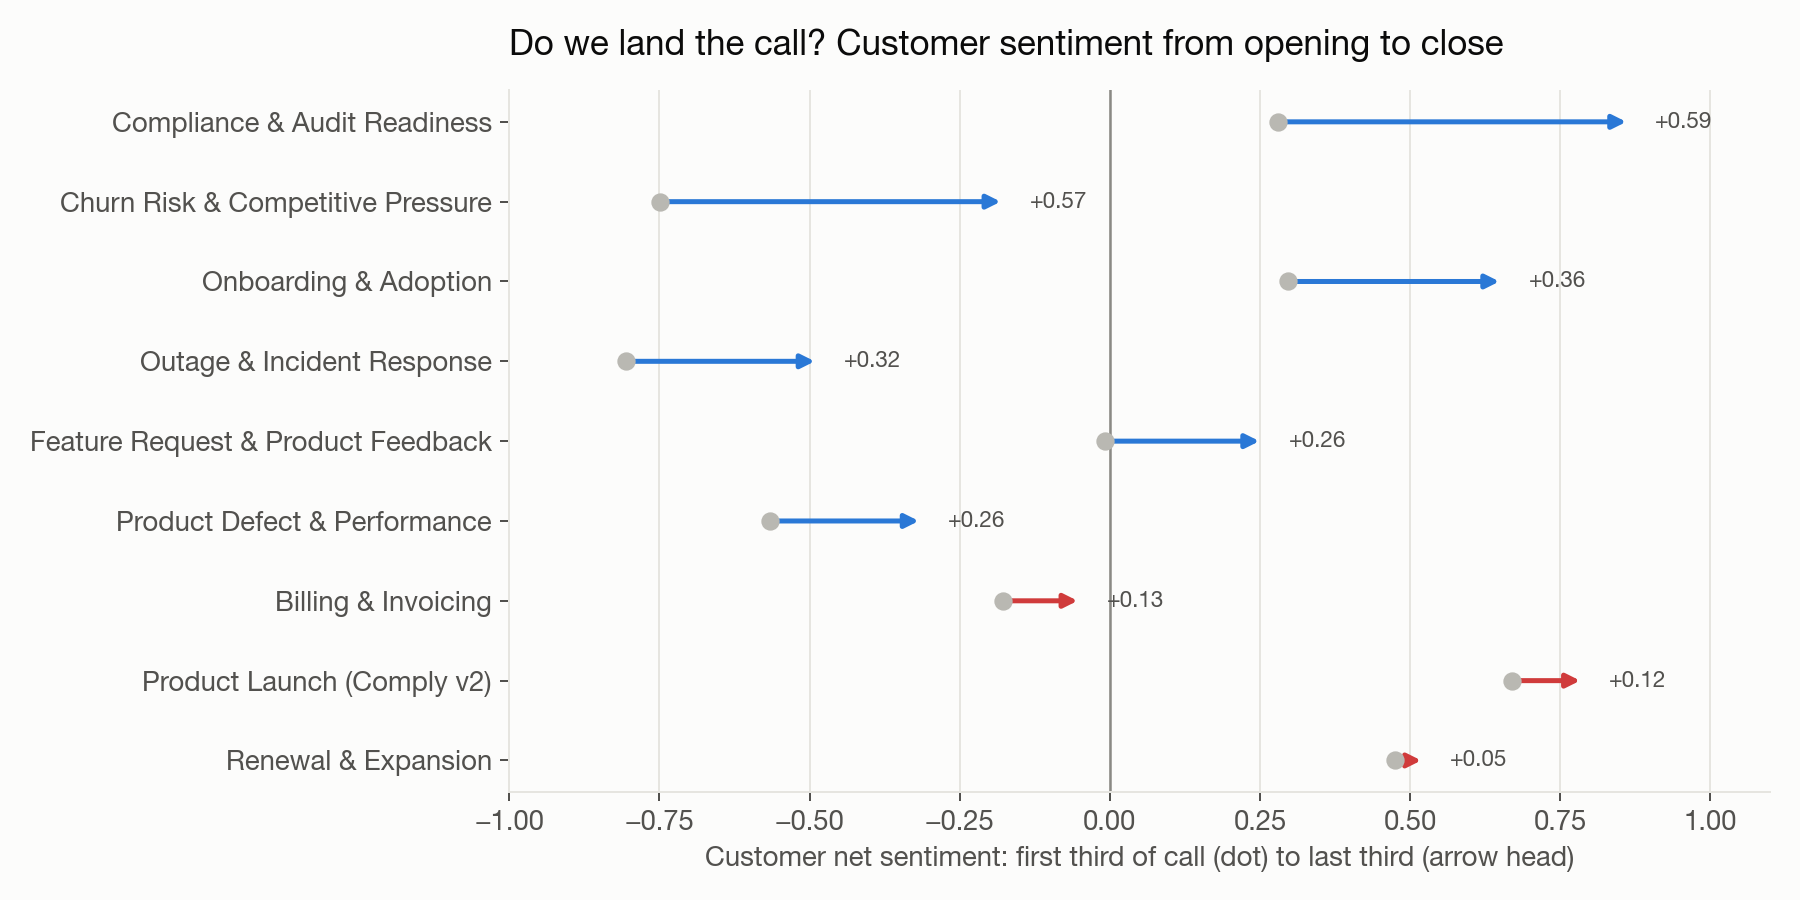

In [13]:
display(Image(OUT / '06_call_arc.png'))

I compared the customer's sentiment in the first third of each call with the last third.
* Customers generally **leave calls happier than they arrived** (+0.36 external, +0.23 support). Reps are good at
  de-escalation in the moment.
* **Churn-risk calls show the biggest in-call recovery (+0.57)** yet those accounts are still evaluating competitors.
  In-call recovery ≠ account recovery. A rep's "great call" feeling is not a retention signal.
* **Billing calls barely move (+0.13).** The rep usually can't fix the invoice on the call and has to "submit a request
  to finance". **Recommendation:** give support agents credit authority up to a threshold.

## 4. Task 3: what else can we see?

Each insight targets a specific stakeholder and comes with evidence (quotes and titles), because a leader won't act
on an insight they can't verify.

### 4.1 Account health and churn risk (CS and sales leaders)
A transparent, additive 0–100 rubric: last sentiment (30), active competitive evaluation (25), vendor-flagged
churn moments (15), support load (10), worsening trend (10), outage exposure (10). It's deliberately not ML: 32 accounts and
no churn labels. A rubric a CS leader can argue with beats a black box.

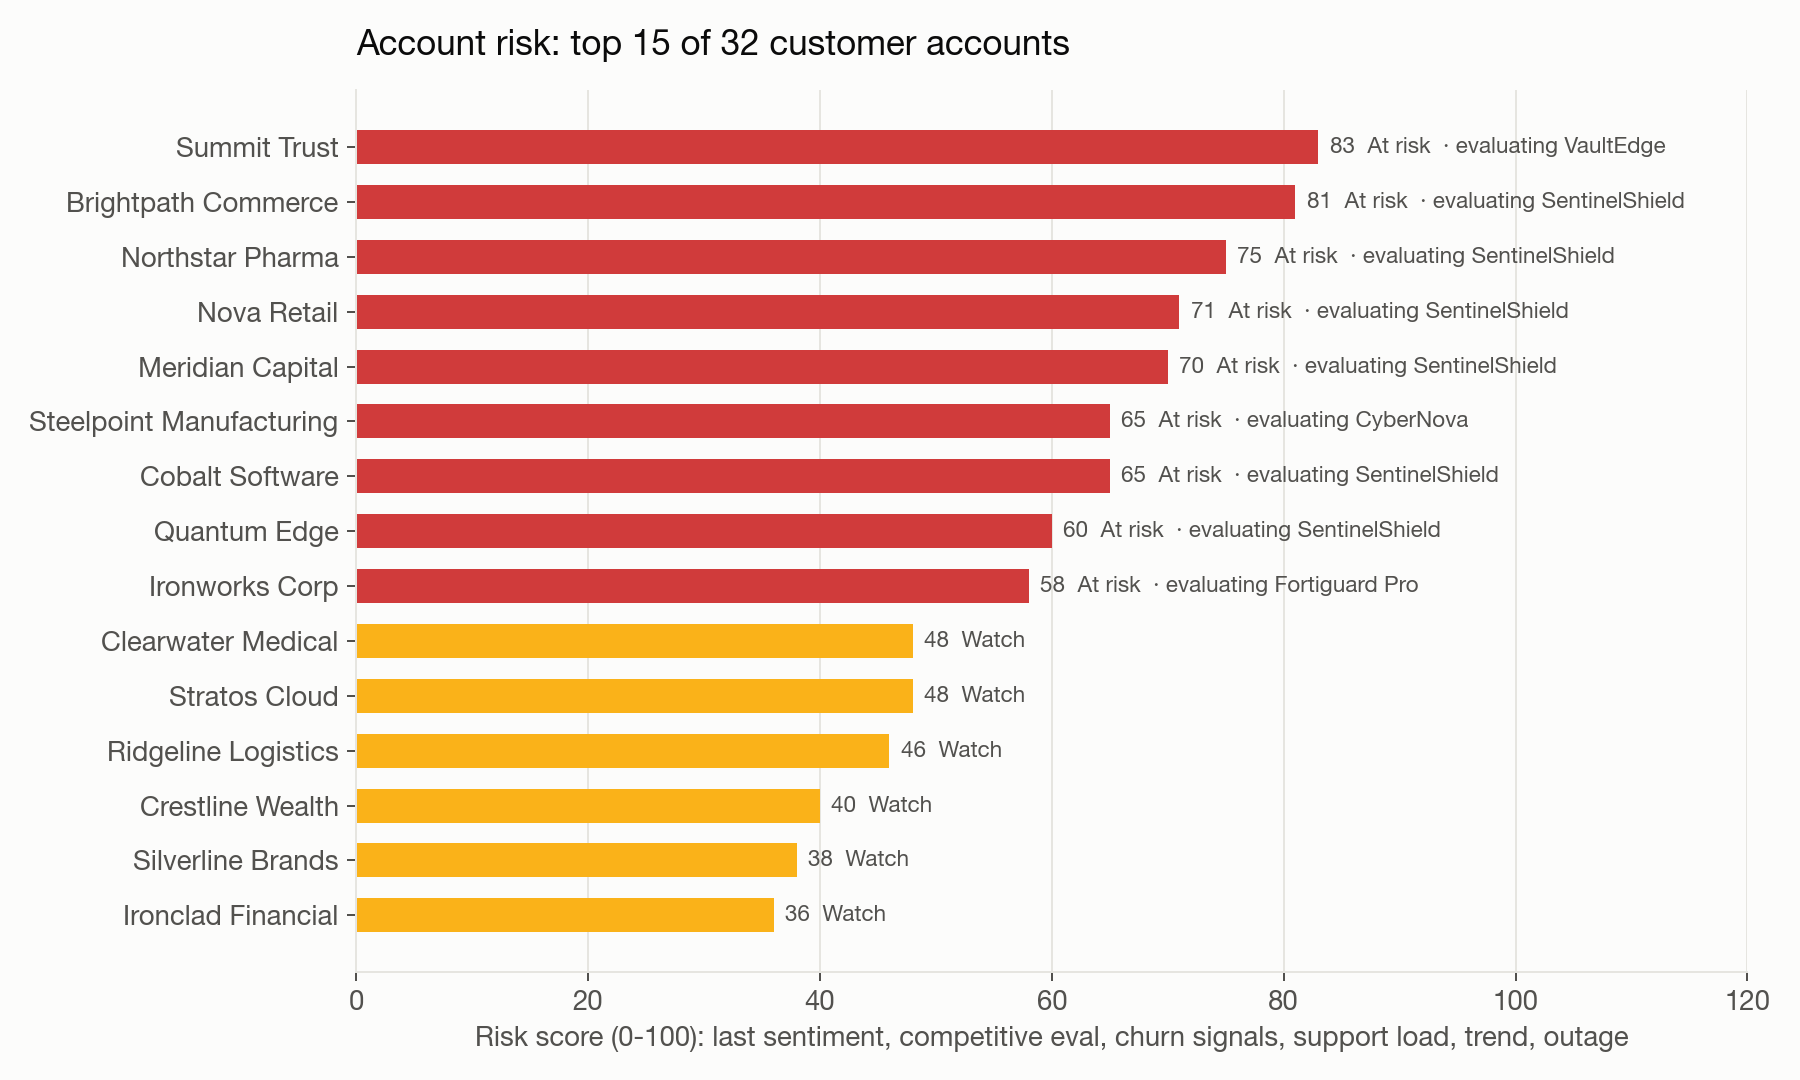

,account,calls,support_calls,first_score,last_score,trend,competitors_named,active_competitive_eval,risk_score,tier,evidence
0,Summit Trust,3,2,3.8,2.4,-1.4,VaultEdge,True,83.0,At risk,Alicia and Gregory express shock and frustration upon learning about the March 10-18 platform outage for the first t...
1,Brightpath Commerce,4,2,3.9,2.6,-1.3,SentinelShield,True,81.0,At risk,Kendra reveals Brightpath has been conducting a six-week security vendor evaluation and is seriously considering Sen...
2,Northstar Pharma,2,1,2.1,2.1,0.0,"SentinelShield, CyberNova",True,75.0,At risk,Frank states he is actively evaluating competitors SentinelShield and CyberNova and has had calls with both in the l...
3,Nova Retail,2,1,2.3,2.6,0.3,SentinelShield,True,71.0,At risk,Stephanie discloses Nova has had two demos with competitor SentinelShield and is close to requesting a formal propos...
4,Meridian Capital,3,2,3.7,3.4,-0.3,SentinelShield,True,70.0,At risk,"Jason states his trading platform has a 15-minute RTO for file-level restores, making the current workaround operati..."
5,Steelpoint Manufacturing,2,1,2.4,2.8,0.4,CyberNova,True,65.0,At risk,"Harold discloses exploratory conversations with competitor CyberNova, driven partly by the outage and partly by prod..."
6,Cobalt Software,2,1,1.8,3.4,1.6,SentinelShield,True,65.0,At risk,"Lauren discloses that procurement is requiring a competitive quote from SentinelShield, signaling renewal risk"
7,Quantum Edge,1,0,2.4,2.4,0.0,SentinelShield,True,60.0,At risk,"Brianna reveals they have been evaluating competitor SentinelShield, which reached out right after the outage and is..."
8,Ironworks Corp,1,0,2.6,2.6,0.0,Fortiguard Pro,True,58.0,At risk,"Catherine reveals they are actively considering leaving Aegis, framing it as a serious internal discussion about fit"
9,Clearwater Medical,2,1,4.8,2.4,-2.4,,False,48.0,Watch,"Natalie raises that the Detect overage may stem from event replay traffic generated by Aegis's own March outage, pot..."


In [14]:
h = I.account_health(m, km)
display(Image(OUT / '07_account_risk.png'))
h[['account','calls','support_calls','first_score','last_score','trend','competitors_named','active_competitive_eval','risk_score','tier','evidence']].head(12)

**9 of 32 accounts are At risk, and every one of them is actively evaluating a competitor (6 name SentinelShield).** Summit Trust tops the list. It has had three calls
(billing → platform concerns → alert delays) and, in its April support call, found out about the March outage
**for the first time**, a month later. That's a communication failure that a transcript tool can catch automatically.

### 4.2 Early warning: did we see it coming? (Engineering leaders)

In [15]:
ew = I.early_warnings(m, s)
display(ew)
I.retro_mentions_of_known_risk(m, s)[['start','title','speaker','text']].head(8)

,start,title,speaker,text,days_before
0,2026-02-05 14:15:00,Detect Team - Sprint Planning,Ananya Sharma,Yeah the pipeline latency investigation has been sitting in my queue and honestly the more I dig into it the more I ...,32
1,2026-02-05 14:15:00,Detect Team - Sprint Planning,Ananya Sharma,"Yeah, so basically the event ingestion pipeline right now has... it's all running through a single processing node w...",32
2,2026-02-16 10:00:00,Weekly Engineering Standup,Mike Romano,"Bit of both, honestly. The dead letter queue piece and the circuit breaker pattern — those are well-understood, I'm ...",21
3,2026-03-02 09:15:00,Detect Team - Sprint Planning,Ananya Sharma,"Right, or at minimum some kind of failover mechanism. If that node goes down, we basically have a blind spot in even...",7


,start,title,speaker,text
0,2026-03-10 13:15:00,INCIDENT: Detect Pipeline Failure - War Room,Ananya Sharma,"It was flagged in the Q4 tech debt review, Tom. I flagged it."
1,2026-03-12 13:45:00,Detect Outage - Customer Impact Assessment,Aisha Johnson,"Yeah. And honestly I didn't have a great answer for her because she asked specifically — she said, 'Was there any al..."
2,2026-03-12 13:45:00,Detect Outage - Customer Impact Assessment,Priya Patel,"We sent a status page update when we detected the issue — well, when the customer flagged it — and then an 'all clea..."
3,2026-03-12 15:45:00,URGENT: Blackridge Investments - Complete Loss of Threat Visibility,Marcus Williams,"Got it, pulling up AGS-229183 right now, okay I see the ticket came in about... forty minutes ago, and I can see you..."
4,2026-03-14 11:45:00,Aegis / Meridian Capital - Service Reliability Discussion,Ravi Gupta,"That's exactly the right question and I want to give you a real answer, not a canned one. The honest truth is — the ..."
5,2026-03-14 14:30:00,Detect Outage - Root Cause Analysis,Ananya Sharma,"Good. And honestly, uh, I think we need to be really transparent in the post-mortem doc about the fact that this ris..."
6,2026-03-17 11:45:00,Aegis / Helix Data - Post-Incident Review,Charles Ng,Two hours before we got any notification. My team was the one who flagged it to your support desk. We noticed our da...
7,2026-03-18 14:45:00,Support Case #7537 - Forge Industries Detect Recovery Confirmation,Dana Moretti,"Okay, right, right. The tenth. Yeah, that's when our alerts just stopped coming through entirely. My team flagged it..."


**The outage's exact root cause was named in internal meetings 32 and 7 days before it happened**, down to the fix
("add redundant processing nodes and a circuit breaker"). In the war room: *"It was flagged in the Q4 tech debt
review. I flagged it."* Then a customer is told *"a known architectural limitation that we hadn't yet prioritized."*

**And it's happening again:** a QA engineer flagged the Protect scheduler concurrency ceiling (QA-1847) in late Feb.
It was deprioritized because of the outage and became the April *"Protect Performance: Scalability Concerns"* meeting.

**Product idea:** a *risk register from transcripts*: extract "single point of failure / tech debt / I'm worried about"
statements from internal calls, link them to a product area, and resurface them when customer calls about that
area start to sour. This is the highest-leverage feature in the deck.

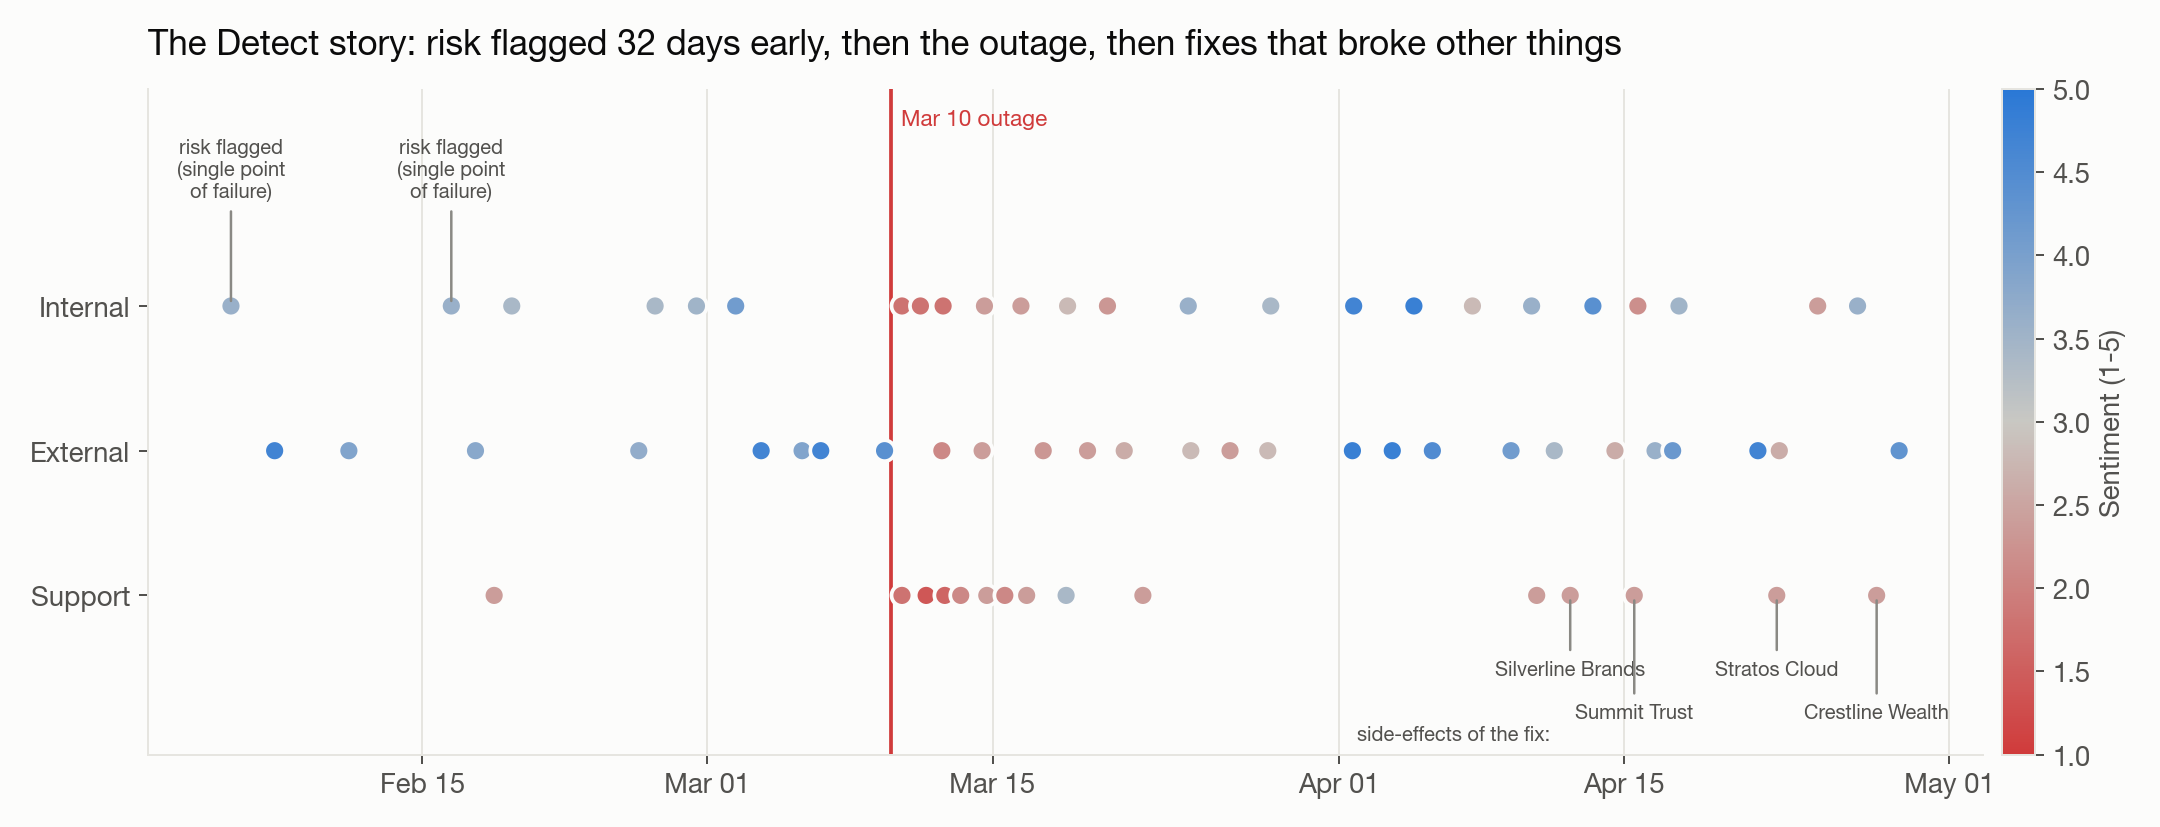

In [16]:
display(Image(OUT / '08_incident_timeline.png'))

### 4.3 Fixes that broke other things, and preventable tickets (Engineering, Support, QA)

In [17]:
display(I.remediation_fallout(m)[['start','account','title','primary_product']])
I.version_hotspots(m)

,start,account,title,primary_product
0,2026-04-12 09:00:00,Silverline Brands,Support Case #9856 - Silverline Brands Backup Window Exceeded,Protect
1,2026-04-15 12:30:00,Summit Trust,Support Case #6147 - Summit Trust Detect Alert Delays,Detect
2,2026-04-22 12:30:00,Stratos Cloud,Support Case #3536 - Stratos Cloud LogVault Integration Timeout,Detect
3,2026-04-27 10:15:00,Crestline Wealth,Support Case #7615 - Crestline Wealth Group Policy Sync Delay,Identity


,start,account,title,product,versions_cited,running_version,known_bug,fix_already_shipped,remediation_build,vendor_sentiment_score,preventable
0,2026-02-18,Vanta Health,Support Case #1750 - Vanta Health Systems SIEM Connector Issue,LogVault,"3.4.1, 3.5.0",3.4.1,True,True,False,2.4,True
1,2026-02-21,Brightpath Commerce,Support Case #6977 - Brightpath Commerce Slow Backup Performance,Protect,"3.4.1, 3.6.0",3.4.1,True,True,False,2.8,True
2,2026-03-16,Silverline Brands,Support Case #3103 - Silverline Brands Detect False Positives After Patch,Detect,4.2.1,4.2.1,False,False,False,2.4,False
3,2026-03-29,Coastal Living,Support Case #8749 - Coastal Living Co SAML Certificate Rotation Bug,Identity,"3.4.1, 3.4.2",3.4.1,True,True,False,2.2,True
4,2026-04-12,Silverline Brands,Support Case #9856 - Silverline Brands Backup Window Exceeded,Protect,"4.1.2, 4.2.0",4.1.2,False,False,True,2.4,False
5,2026-04-22,Stratos Cloud,Support Case #3536 - Stratos Cloud LogVault Integration Timeout,Detect,4.1.2,4.1.2,False,False,True,2.4,False


* **4 support calls in April trace back to the outage remediation itself**, across *three* products: Summit Trust
  (tenant moved to an overloaded cluster), Stratos (circuit-breaker payload threshold in build 4.1.2 dropping LogVault
  events), Silverline (backup throughput down after network routing changes), Crestline (Identity sync queue on a
  shared cluster). The fix to Detect had a blast radius into Protect and Identity.
* **Version 3.4.1 is a recurring bad release across three products** (LogVault connector, Protect backup agent,
  Identity). In each case **a fix already existed** (3.5.0 / 3.6.0 / 3.4.2) but the customer hadn't upgraded.
  These are preventable tickets → **proactive "you're on a version with a known bug" outreach.**

### 4.4 Feature-gap backlog (Product managers)

In [18]:
fb, fg = I.feature_gap_backlog(m, km)
fb

,primary_product,requests,accounts,avg_sentiment_of_asking_calls,examples
0,Comply,12,10,4.26,"Wayne asks about SOC 2 compliance reporting, signaling potential expansion opportunity with the Aegis Comply add-on ..."
1,Identity,11,9,3.95,Gregory requests proactive seat-count threshold alerts to avoid discovering overages on future invoices || Mina flag...
2,Detect,7,7,2.44,"Julia challenges the platform's architecture, pointing out that a single component failure took down the entire moni..."
3,Protect,5,4,4.34,"Sarah confirms that granular file-level restore is not currently supported in Aegis Protect, validating Jason's susp..."
4,LogVault,1,1,2.40,"Raymond Burke discovers the retry_on_timeout parameter is undocumented, prompting Dr. Cheng to enumerate a list of s..."


Counting *distinct accounts* asking (not mentions) makes this a defensible prioritisation input. Comply and Identity
gaps come from **happy** accounts (sentiment ~4): these are expansion asks. Detect gaps come from **unhappy** accounts
(2.4): these are retention asks. Same "feature request" label, very different urgency.

### 4.5 Competitive intelligence (Sales, PMM)

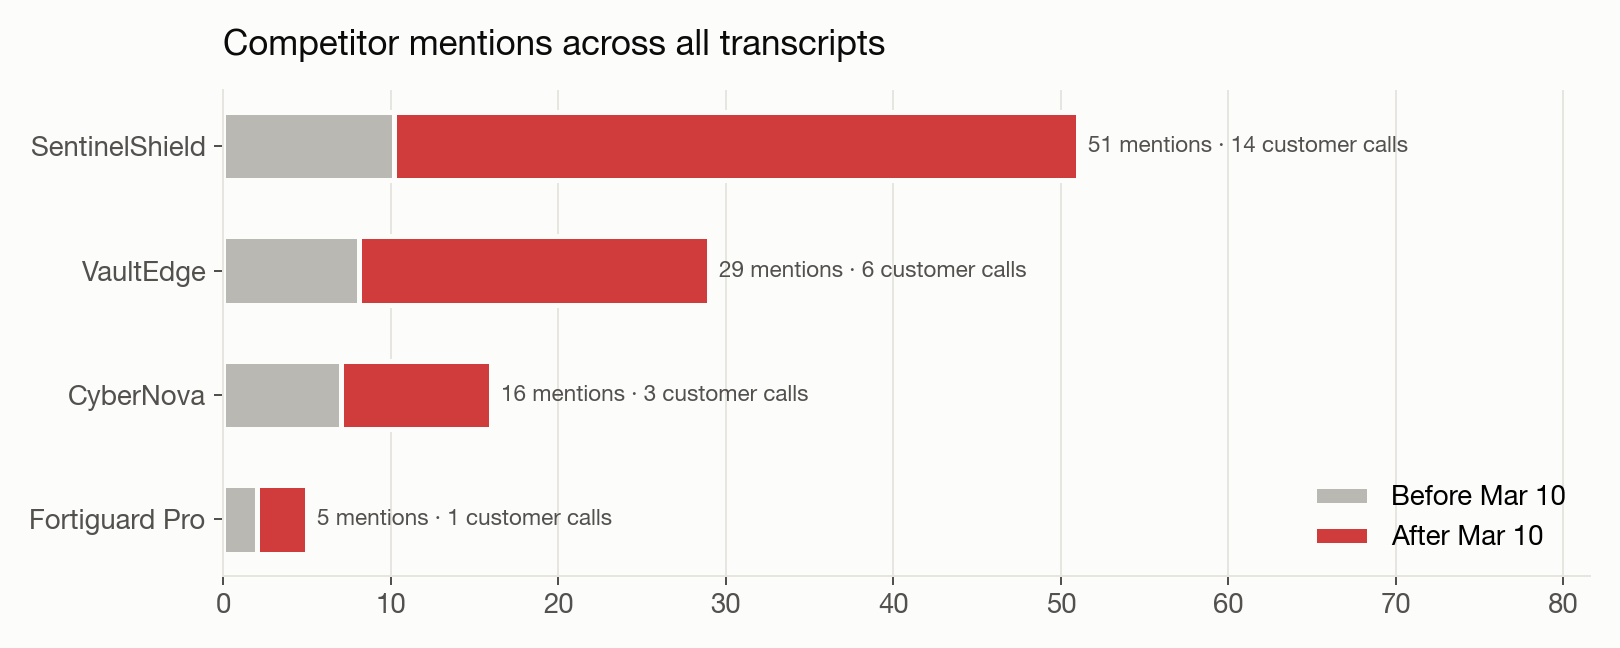

,competitor,mentions,customer_calls,post_outage_share,products_in_context,sample_quote
0,SentinelShield,51,14,0.80,"Detect, Identity, Protect","Probably SentinelShield, just because they've been pretty aggressive in our space lately. I don't have a strong pull..."
1,VaultEdge,29,6,0.72,"Identity, Protect, Detect","Agreed. Aisha, one thing I do want to put on the table — and I want to be clear this isn't a threat, it's just due d..."
2,CyberNova,16,3,0.56,"Detect, Identity, Protect","I'd be open to hearing the numbers on that. I'll be honest with you though — and this is not meant as a threat, it's..."
3,Fortiguard Pro,5,1,0.60,"Identity, Comply","Yeah, we've been talking to Fortiguard Pro. They reached out to us actually, about six weeks ago, and their pitch wa..."


In [19]:
display(Image(OUT / '09_competitors.png'))
I.competitor_intel(m, s)[['competitor','mentions','customer_calls','post_outage_share','products_in_context','sample_quote']]

SentinelShield is mentioned 51 times across 14 customer calls, **80% after the outage**, pitched on uptime SLA
(99.9% vs. Aegis's 99.5%). The internal Win/Loss review attributes ≥5 lost deals to the outage. Sales needs a
reliability narrative (post-mortem + 30-day clean window); Product should consider a public SLA upgrade.

### 4.6 Billing friction is a product problem (Finance, Product)

In [20]:
I.billing_friction(m)[['start','account','title','root_cause_hint','customer_unaware_of_usage','vendor_sentiment_score']]

,start,account,title,root_cause_hint,customer_unaware_of_usage,vendor_sentiment_score
0,2026-02-06 09:15:00,Summit Trust,Support Case #9279 - Summit Trust Billing Inquiry,seat,True,3.8
1,2026-02-25 15:00:00,Atlas Precision,Aegis / Atlas Precision - Contract Discussion,new production facilities,False,3.7
2,2026-02-27 13:00:00,Brightpath Commerce,Support Case #7572 - Brightpath Commerce Invoice Discrepancy,policy change,True,3.7
3,2026-04-10 17:30:00,Clearwater Medical,Support Case #8179 - Clearwater Medical Overage Charges Dispute,no knowledge of plan limits,True,2.4
4,2026-04-18 09:15:00,Silverline Brands,Support Case #7570 - Silverline Brands Comply v2 License Upgrade,proration,False,3.9


Every overage dispute has the same shape: **the customer didn't know they were over** (test accounts never
deprovisioned, a backup policy change, report generation during the v2 launch "with no in-app alerts"). One customer
literally asked for *"proactive seat-count threshold alerts."* **Usage alerts in-product** would remove a whole
support category.

### 4.7 Key-person load (CS and support ops)

In [21]:
I.owner_load(m, s, h).head(8)

,speaker,at_risk_calls,at_risk_accounts
0,Sarah Chen,5,4
1,Maria Santos,4,4
2,David Kim,3,3
3,Marcus Williams,3,3
4,Aisha Johnson,2,2
5,Elena Vasquez,2,2
6,Lisa Park,2,2
7,Daniel Okafor,1,1


Sarah Chen (support) and Maria Santos (CSM) are each on calls with 4 of the 9 at-risk accounts. If she leaves or burns out, that context goes with
her. A transcript tool can show relationship concentration that no CRM field captures.

### 4.8 A caution: talk-time ratio

In [22]:
tr = I.talk_ratio(m)
print('corr(customer talk share, sentiment) =', round(tr[['customer_talk_share','vendor_sentiment_score']].corr().iloc[0,1], 2))
tr.groupby('talk_bucket', observed=True).agg(calls=('meeting_id','count'), sentiment=('vendor_sentiment_score','mean')).round(2)

corr(customer talk share, sentiment) = -0.42


,calls,sentiment
talk_bucket,,
rep-dominated (<40%),9,4.26
balanced,31,3.74


The naive reading ("calls where the rep talks more are happier, so reps should talk more") is **wrong**: the causation
runs the other way. Unhappy customers talk more because they're explaining what went wrong. I include this to show
the kind of conclusion the product should *not* surface without context.

## 5. Limitations and next steps
* **Small n.** 100 calls, 2–12 per week. Trends are directional; I report shapes and sizes, not significance.
* **Vendor-derived fields** (summary, key moments, topics) are themselves LLM outputs. I validated sentiment
  independently; key-moment types were spot-checked, not audited.
* **Gold labels** are mine (single annotator, LLM-assisted reading of summaries). A second annotator would provide
  inter-rater agreement.
* **Account risk** has no ground truth (we don't see renewals/churn outcomes). Next step: backtest against CRM outcomes.
* **Next:** run the LLM classifier in parallel for disagreement review, build the transcript risk register, link
  support tickets ↔ internal incident calls automatically, and add commitment tracking (did the action items from
  call N show up as done in call N+1?).